
# Week 2: Financial Sentiment Analysis Prototype

**Project:** Market Stress Early-Warning System for U.S. Equity Markets

**Focus:** NLP / Financial Sentiment Analysis

## Objective

This notebook prepares cleaned SEC filing paragraphs from Week 1 and tests a pretrained financial sentiment model (FinBERT).

The goal is to classify financial text as positive, negative, or neutral and explore how these sentiment signals could contribute to a market stress early-warning system.


In [1]:

# Step 1: Load cleaned SEC filing paragraphs

import pandas as pd
from pathlib import Path

data_path = Path("../data/processed/sec/paragraphs.parquet")

paras = pd.read_parquet(data_path)

print("Total paragraphs:", len(paras))
print("Duplicate paragraphs:", paras.duplicated(
    subset=["ticker", "filing_date", "text"]
).sum())

display(paras[["ticker", "form", "section", "text"]].head())


Total paragraphs: 5600
Duplicate paragraphs: 0


,ticker,form,section,text
0,NVDA,10-K,front matter,Indicate by check mark whether the registrant ...
1,NVDA,10-K,front matter,The aggregate market value of the voting stock...
2,NVDA,10-K,front matter,The number of shares of common stock outstandi...
3,NVDA,10-K,front matter,Portions of the registrant's Proxy Statement f...
4,NVDA,10-K,front matter,Investors and others should note that we annou...


In [2]:

# Step 2: Prepare SEC text for sentiment analysis

import re

sentiment_df = paras.copy()

# Remove missing and empty text
sentiment_df = sentiment_df.dropna(subset=["text"])
sentiment_df["clean_text"] = sentiment_df["text"].apply(
    lambda text: re.sub(r"\s+", " ", str(text)).strip()
)

sentiment_df = sentiment_df[
    sentiment_df["clean_text"].str.len() > 0
].copy()

# Select relevant financial disclosure sections
sentiment_df = sentiment_df[
    (
        (sentiment_df["form"] == "10-K") &
        (sentiment_df["section"].isin(["Item 1A", "Item 7"]))
    )
    |
    (
        (sentiment_df["form"] == "10-Q") &
        (sentiment_df["section"].isin(["Item 1A", "Item 2"]))
    )
].copy()

print("Paragraphs ready for sentiment analysis:", len(sentiment_df))
display(sentiment_df[["ticker", "form", "section", "clean_text"]].head())


Paragraphs ready for sentiment analysis: 2141


,ticker,form,section,clean_text
99,NVDA,10-K,Item 1A,"In evaluating NVIDIA, the following risk facto..."
100,NVDA,10-K,Item 1A,If we fail to meet the evolving needs of our m...
101,NVDA,10-K,Item 1A,Our accelerated computing platforms address fo...
102,NVDA,10-K,Item 1A,"• timely identify emerging industry changes, a..."
103,NVDA,10-K,Item 1A,• develop infrastructure needed to scale our b...


In [4]:

%pip install transformers torch


  Using cached transformers-5.22.1-py3-none-any.whl.metadata (31 kB)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached pyyaml-6.0.3-cp314-cp314-win_amd64.whl.metadata (2.4 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-win_amd64.whl.metadata (10 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.8.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached httpx2-2.16.0-py3-none-any.whl.metadata (10 kB)
  Using cached httpcore2-2.16.0-py3-none-any.whl.metadata (27 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
Using cached transformers-5.22.1-py3-none-any.whl (13.1 MB)
Using cached huggingface_hub-2.4.0-py3-none-any.whl (857 kB)
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using cached hf_xet-1.8.0-cp38-abi3-win_amd64.whl (3.9 MB)
Using cached httpx2-2.16.0-py3-none-any.whl (97 kB)
Using cached httpcore2-2.16.0-py

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To 

## 3. Pretrained Financial Sentiment Model (FinBERT)

In [5]:

# Step 3: Test pretrained FinBERT on SEC filing paragraphs

from transformers import pipeline

model_name = "ProsusAI/finbert"

sentiment_model = pipeline(
    "text-classification",
    model=model_name,
    tokenizer=model_name,
    device=-1
)

sample = sentiment_df.head(5).copy()

results = sentiment_model(
    sample["clean_text"].tolist(),
    truncation=True,
    max_length=512
)

sample["sentiment"] = [r["label"] for r in results]
sample["confidence"] = [round(r["score"], 4) for r in results]

display(sample[["ticker", "section", "sentiment", "confidence"]])


c:\Users\LATITUDE\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\LATITUDE\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\LATITUDE\.cache\huggingface\hub\models--ProsusAI--finbert. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as a

,ticker,section,sentiment,confidence
99,NVDA,Item 1A,negative,0.7821
100,NVDA,Item 1A,negative,0.9200
101,NVDA,Item 1A,neutral,0.7320
102,NVDA,Item 1A,positive,0.7886
103,NVDA,Item 1A,positive,0.8131


In [6]:

# Step 4: Test FinBERT on a sample from each company

test_sample = (
    sentiment_df.groupby("ticker", group_keys=False)
    .sample(n=10, random_state=42)
    .copy()
)

predictions = sentiment_model(
    test_sample["clean_text"].tolist(),
    truncation=True,
    max_length=512,
    batch_size=8
)

test_sample["sentiment"] = [p["label"] for p in predictions]
test_sample["confidence"] = [round(p["score"], 4) for p in predictions]

print("Total paragraphs tested:", len(test_sample))
display(pd.crosstab(test_sample["ticker"], test_sample["sentiment"]))


Total paragraphs tested: 40


sentiment,negative,neutral,positive
ticker,,,
AAPL,2,5,3
GOOGL,2,8,0
MSFT,5,2,3
NVDA,6,4,0


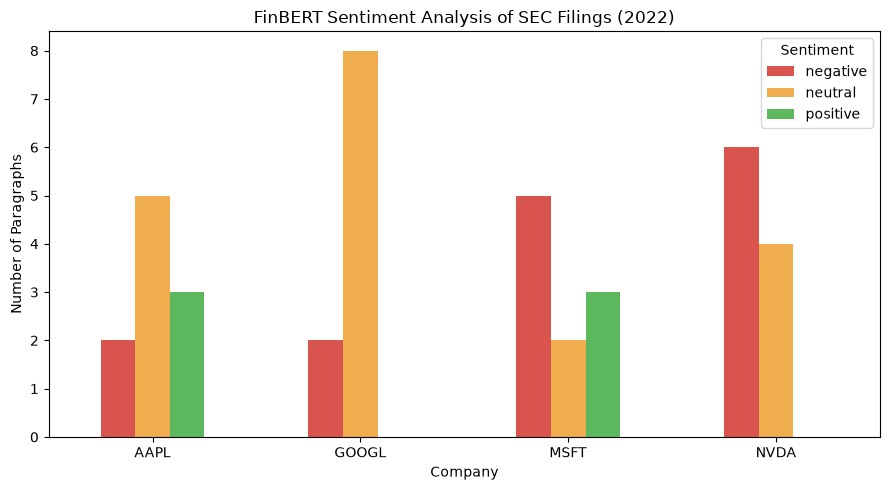

In [7]:

# Step 5: Visualize sentiment results by company

import matplotlib.pyplot as plt

sentiment_counts = pd.crosstab(
    test_sample["ticker"],
    test_sample["sentiment"]
)

sentiment_counts = sentiment_counts.reindex(
    columns=["negative", "neutral", "positive"],
    fill_value=0
)

sentiment_counts.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#D9534F", "#F0AD4E", "#5CB85C"]
)

plt.title("FinBERT Sentiment Analysis of SEC Filings (2022)")
plt.xlabel("Company")
plt.ylabel("Number of Paragraphs")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()



## 4. Results and Observations

FinBERT was tested on 40 SEC filing paragraphs from four companies: Apple, Google, Microsoft, and NVIDIA.

### Key Findings
- 15 paragraphs were classified as negative, 19 as neutral, and 6 as positive.
- NVIDIA had the highest number of negative predictions (6 out of 10).
- Google had the highest number of neutral predictions (8 out of 10).
- Microsoft had 5 negative, 2 neutral, and 3 positive predictions.
- Apple had a mix of all three sentiment categories.

### Limitations
- Only 40 paragraphs were tested, so these results are preliminary.
- Amazon was excluded because its paragraphs were labeled as "front matter" rather than the target SEC sections.
- Some section labels may be inaccurate due to differences in filing formats.
- FinBERT predictions have not yet been manually validated.
- These sentiment predictions do not directly establish market stress or predict stock prices.

### Conclusion
The prototype successfully demonstrates that a pretrained financial sentiment model can classify SEC filing paragraphs into positive, negative, and neutral categories. Future work should improve SEC section tagging, validate sentiment predictions, and investigate whether sentiment signals relate to market stress.
